# How Generative AI Creates Content: A Technical Deep Dive
Generative AI models create content through a sophisticated process of predicting the next token (word, character, or subword) based on the context of previous tokens. At their core, these models use attention mechanisms to weigh the importance of different parts of the input sequence, creating probability distributions over possible next tokens. Each generated word builds upon this complex interplay of pattern recognition and statistical prediction, with the model continuously updating its internal state as it produces new content. 

This notebook provides interactive visualizations of these attention patterns and probability distributions in action, allowing you to observe how a language model "thinks" while generating text. To truly understand the mechanics behind AI text generation, we encourage you to download this notebook, run the pre-written code, and experiment with different prompts to see how the model's attention shifts and how probability distributions evolve during the generation process.

## Token-Based Generation Process
The fundamental mechanism of content generation in transformer models involves predicting tokens sequentially. Let's examine this process with clean, executable code:

In [4]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Load pre-trained model and tokenizer
model_name = "gpt2"  # A small model for demonstration
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

# Set the model to evaluation mode
model.eval()

# Define a business-relevant prompt
prompt = "Generative AI can help data scientists by"

# Tokenize the prompt
input_ids = tokenizer.encode(prompt, return_tensors='pt')
prompt_length = len(input_ids[0])

# Generate text token by token with clear visualization
generated = input_ids.clone()
generation_steps = []
all_token_probs = []

# Generate 15 new tokens to keep the example concise but informative
for i in range(15):
    # Get model's prediction (logits) for next token
    with torch.no_grad():
        outputs = model(generated)
        next_token_logits = outputs.logits[:, -1, :]
    
    # Convert logits to probabilities
    next_token_probs = torch.softmax(next_token_logits, dim=-1)[0]
    
     # Store the full probability distribution for analysis
    all_token_probs.append(next_token_probs.squeeze().numpy())
    
    # Store top predictions before sampling
    top_predictions = {
        "step": i + 1,
        "top_tokens": torch.topk(next_token_probs, 10),
        "context": tokenizer.decode(generated[0])
    }
    
    # Sample from the distribution
    next_token_id = torch.multinomial(next_token_probs, num_samples=1).item()
    next_token_prob = next_token_probs[next_token_id].item()
    next_token_text = tokenizer.decode([next_token_id])
    
    # Add selected token info to the step data
    top_predictions["selected"] = {
        "token": next_token_text,
        "id": next_token_id,
        "probability": next_token_prob
    }
    
    generation_steps.append(top_predictions)
    
    # Add the new token to our sequence
    generated = torch.cat([generated, torch.tensor([[next_token_id]])], dim=1)

# Display the full generated text
print(f"Input prompt: {prompt}")
print(f"Generated text: {tokenizer.decode(generated[0], skip_special_tokens=True)}")
print("\nToken-by-token generation process:")

# Show detailed generation process
for step in generation_steps:
    print(f"\nStep {step['step']}:")
    print(f"Context so far: {step['context']}")
    print(f"Top 10 token predictions:")
    for i in range(10):
        token_id = step['top_tokens'].indices[i].item()
        print(token_id)
        token_text = tokenizer.decode([token_id])
        token_prob = step['top_tokens'].values[i].item()
        print(f"  '{token_text}' (ID: {token_id}) - Probability: {token_prob:.4f}")
    
    print(f"Selected token: '{step['selected']['token']}' (ID: {step['selected']['id']}) - " 
          f"Probability: {step['selected']['probability']:.4f}")

Input prompt: Generative AI can help data scientists by
Generated text: Generative AI can help data scientists by recognizing their true roles in improving future generations' healthcare systems at scale because it

Token-by-token generation process:

Step 1:
Context so far: Generative AI can help data scientists by
Top 10 token predictions:
4955
  ' providing' (ID: 4955) - Probability: 0.0588
5742
  ' helping' (ID: 5742) - Probability: 0.0366
1642
  ' making' (ID: 1642) - Probability: 0.0302
5086
  ' allowing' (ID: 5086) - Probability: 0.0300
13720
  ' identifying' (ID: 13720) - Probability: 0.0258
4547
  ' understanding' (ID: 4547) - Probability: 0.0256
4441
  ' creating' (ID: 4441) - Probability: 0.0250
3557
  ' autom' (ID: 3557) - Probability: 0.0184
22712
  ' analyzing' (ID: 22712) - Probability: 0.0182
15453
  ' generating' (ID: 15453) - Probability: 0.0172
Selected token: ' recognizing' (ID: 22650) - Probability: 0.0035

Step 2:
Context so far: Generative AI can help data scient

## Probability Distribution Analysis
Each token generation step produces a probability distribution over the model's entire vocabulary. Let's examine what this distribution actually looks like for the first step. Remember that this distribution gets sampled from to produce the next token. Only greedy sampling would always grab the highest probability token.

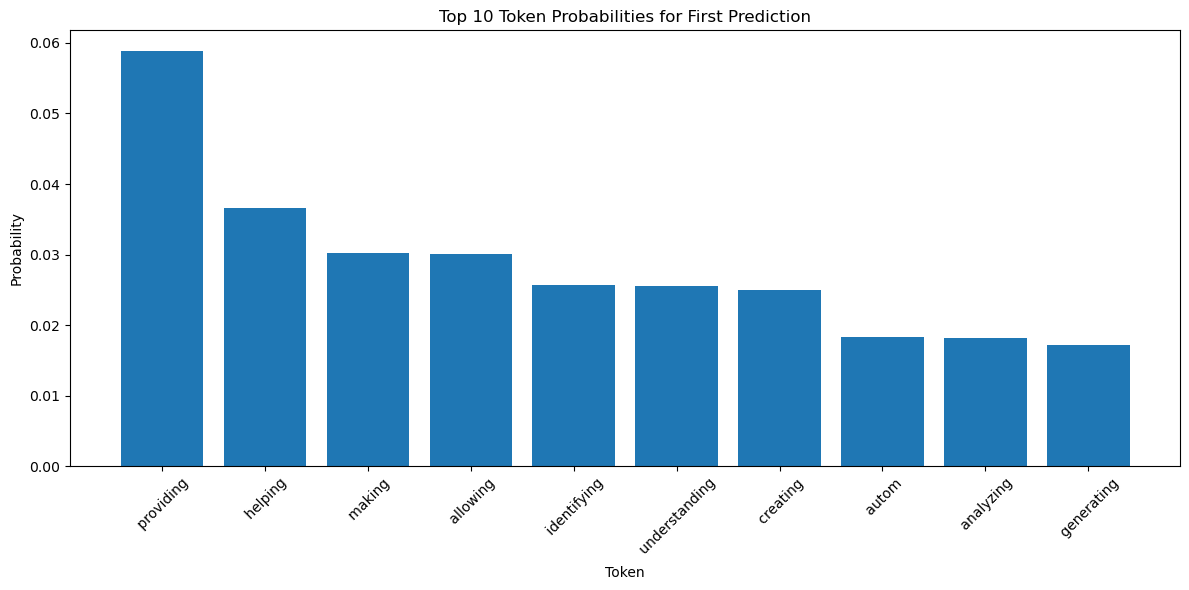

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Analyze the first token probability distribution
first_token_probs = all_token_probs[0]

# Get top 10 tokens and their probabilities
top_indices = np.argsort(first_token_probs)[-10:][::-1]
top_probs = first_token_probs[top_indices]
top_tokens = [tokenizer.decode([idx]) for idx in top_indices]

# Visualize the distribution
plt.figure(figsize=(12, 6))
plt.bar(top_tokens, top_probs)
plt.title('Top 10 Token Probabilities for First Prediction')
plt.xlabel('Token')
plt.ylabel('Probability')
plt.xticks(rotation=45)
plt.tight_layout()

This visualization shows that typically only a small subset of tokens have significant probability mass, with the distribution having a long tail. This is why sampling methods like top-k and nucleus sampling are incredibly effective. Without proper sampling, as you can see from above, the generation model can select tokens with small probabilities due to sampling chance.

## Sampling Methods Implementation
Let's compare different sampling methods with a clear implementation that shows how each method affects generation quality:

NOTE: This different sampling methods and mechanisms are handled by internal code usually and is set via parameter arguments typically. The code below is just to demonstrate these inner workings and would not need to be implemented separetley. You are encouraged to play around with different parameter values.

In [6]:
def generate_with_sampling(prompt, method, **params):
    """Generate text using different sampling methods with detailed output."""
    input_ids = tokenizer.encode(prompt, return_tensors='pt')
    max_length = params.get('max_length', 50)
    
    # Initialize generation
    generated = input_ids.clone()
    
    # Store token selection info for each step
    generation_info = []
    
    # Generate new tokens
    for _ in range(max_length - len(input_ids[0])):
        # Get model's prediction for next token
        with torch.no_grad():
            outputs = model(generated)
        
        next_token_logits = outputs.logits[:, -1, :][0]  # Get logits for next token
        
        # Apply temperature if specified
        temperature = params.get('temperature', 1.0)
        if temperature != 1.0:
            scaled_logits = next_token_logits / temperature
        else:
            scaled_logits = next_token_logits.clone()
        
        # Track original top tokens before sampling
        orig_top_tokens = torch.topk(torch.softmax(next_token_logits, dim=-1), 5)
        
        # Apply different sampling methods
        if method == 'greedy':
            # Greedy sampling - always take highest probability token
            next_token_id = torch.argmax(scaled_logits).unsqueeze(0)
            next_token_prob = torch.softmax(scaled_logits, dim=-1)[next_token_id].item()
            sampling_details = "Greedy: Selected highest probability token"
            
        elif method == 'top_k':
            # Top-k sampling
            k = params.get('k', 50)
            top_k_logits, top_k_indices = torch.topk(scaled_logits, k)
            
            # Create mask for top-k tokens
            mask = torch.zeros_like(scaled_logits)
            mask.scatter_(-1, top_k_indices, 1)
            masked_logits = torch.where(mask.bool(), scaled_logits, torch.tensor(-float('inf')))
            
            # Sample from filtered distribution
            filtered_probs = torch.softmax(masked_logits, dim=-1)
            next_token_id = torch.multinomial(filtered_probs, num_samples=1).item()
            next_token_prob = filtered_probs[next_token_id].item()
            sampling_details = f"Top-k: Selected from top {k} tokens"
            
        elif method == 'nucleus':
            # Nucleus (top-p) sampling
            p = params.get('p', 0.9)
            
            # Sort logits in descending order
            sorted_logits, sorted_indices = torch.sort(scaled_logits, descending=True)
            sorted_probs = torch.softmax(sorted_logits, dim=-1)
            cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
            
            # Find tokens within the probability mass p
            sorted_indices_to_remove = cumulative_probs > p
            # Keep tokens that contribute to the top p probability mass
            sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
            sorted_indices_to_remove[0] = False
            
            # Mask out tokens outside the nucleus
            indices_to_remove = torch.zeros_like(scaled_logits, dtype=torch.bool)
            indices_to_remove.scatter_(-1, sorted_indices[sorted_indices_to_remove], True)
            masked_logits = torch.where(indices_to_remove, torch.tensor(-float('inf')), scaled_logits)
            
            # Sample from filtered distribution
            filtered_probs = torch.softmax(masked_logits, dim=-1)
            next_token_id = torch.multinomial(filtered_probs, num_samples=1).item()
            next_token_prob = filtered_probs[next_token_id].item()
            
            # Calculate what percentage of the vocabulary was considered
            tokens_considered = (~indices_to_remove).sum().item()
            percent_vocab = tokens_considered / len(scaled_logits) * 100
            sampling_details = f"Nucleus: Selected from top {p:.1f} probability mass ({tokens_considered} tokens, {percent_vocab:.1f}% of vocab)"
            
        # Record info about this generation step
        step_info = {
            "original_top_tokens": [(tokenizer.decode([orig_top_tokens.indices[i].item()]), 
                                   orig_top_tokens.values[i].item()) 
                                  for i in range(5)],
            "selected_token": tokenizer.decode(next_token_id),
            "selected_prob": next_token_prob,
            "sampling_method": method,
            "sampling_details": sampling_details
        }
        generation_info.append(step_info)
        
        # Add token to generated sequence
        generated = torch.cat([generated, torch.tensor([[next_token_id]])], dim=1)
        
        # Stop if we generate an EOS token
        if next_token_id == tokenizer.eos_token_id:
            break
    
    # Prepare the result
    result = {
        "prompt": prompt,
        "method": method,
        "parameters": params,
        "generated_text": tokenizer.decode(generated[0], skip_special_tokens=True),
        "generation_info": generation_info
    }
    
    return result

# Compare different sampling methods
prompt = "Data scientists can leverage generative AI for business analytics by"

greedy_result = generate_with_sampling(prompt, 'greedy')
topk_result = generate_with_sampling(prompt, 'top_k', k=50, temperature=0.7)
nucleus_result = generate_with_sampling(prompt, 'nucleus', p=0.95, temperature=0.8)

# Display results
print("GREEDY SAMPLING:")
print(f"Generated text: {greedy_result['generated_text']}")
print("\nFirst 3 generation steps:")
for i, step in enumerate(greedy_result['generation_info'][:3]):
    print(f"\nStep {i+1}:")
    print(f"Top 5 original tokens: {step['original_top_tokens']}")
    print(f"Selected: '{step['selected_token']}' - Probability: {step['selected_prob']:.4f}")
    print(f"Method: {step['sampling_details']}")

print("\n" + "="*80 + "\n")

print("TOP-K SAMPLING:")
print(f"Generated text: {topk_result['generated_text']}")
print("\nFirst 3 generation steps:")
for i, step in enumerate(topk_result['generation_info'][:3]):
    print(f"\nStep {i+1}:")
    print(f"Top 5 original tokens: {step['original_top_tokens']}")
    print(f"Selected: '{step['selected_token']}' - Probability: {step['selected_prob']:.4f}")
    print(f"Method: {step['sampling_details']}")

print("\n" + "="*80 + "\n")

print("NUCLEUS SAMPLING:")
print(f"Generated text: {nucleus_result['generated_text']}")
print("\nFirst 3 generation steps:")
for i, step in enumerate(nucleus_result['generation_info'][:3]):
    print(f"\nStep {i+1}:")
    print(f"Top 5 original tokens: {step['original_top_tokens']}")
    print(f"Selected: '{step['selected_token']}' - Probability: {step['selected_prob']:.4f}")
    print(f"Method: {step['sampling_details']}")

GREEDY SAMPLING:
Generated text: Data scientists can leverage generative AI for business analytics by using the same techniques that are used to analyze data from the Internet.

The company's research team is led by Dr. Michael J. Karp, a professor of computer science at the

First 3 generation steps:

Step 1:
Top 5 original tokens: [(' using', 0.10768698155879974), (' leveraging', 0.05206528306007385), (' building', 0.03421095758676529), (' creating', 0.029891276732087135), (' combining', 0.029469870030879974)]
Selected: ' using' - Probability: 0.1077
Method: Greedy: Selected highest probability token

Step 2:
Top 5 original tokens: [(' the', 0.06671921163797379), (' machine', 0.044429659843444824), (' a', 0.04055935889482498), (' AI', 0.0361798033118248), (' data', 0.024386342614889145)]
Selected: ' the' - Probability: 0.0667
Method: Greedy: Selected highest probability token

Step 3:
Top 5 original tokens: [(' same', 0.030496396124362946), (' AI', 0.024371791630983353), (' tools', 0

## Implementing Attention Visualization
To help understand how transformer models make decisions during text generation, here's a practical implementation for visualizing attention patterns. This visual looks at the attention for the first step but can be abstracted to steps beyond that. This can be particularly useful in helping to explain the model’s ‘understanding’ and can be also applied to more traditional machine learning uses of transformers like classification.

NOTE: You will a special token character 'Ġ' show up. This is used by the tokenizer to denote a space. Other tokenizers use different special characters as well (think back to BERT) including '_' to denote empty spaces.

Prompt: 'Generative AI can improve data analysis by'

Tokens ranked by attention weight (for predicting the next token):
  'Ġimprove': 0.2676
  'Gener': 0.1528
  'Ġdata': 0.1352
  'Ġcan': 0.1092
  'Ġby': 0.1004
  'Ġanalysis': 0.0996
  'ĠAI': 0.0943
  'ative': 0.0409


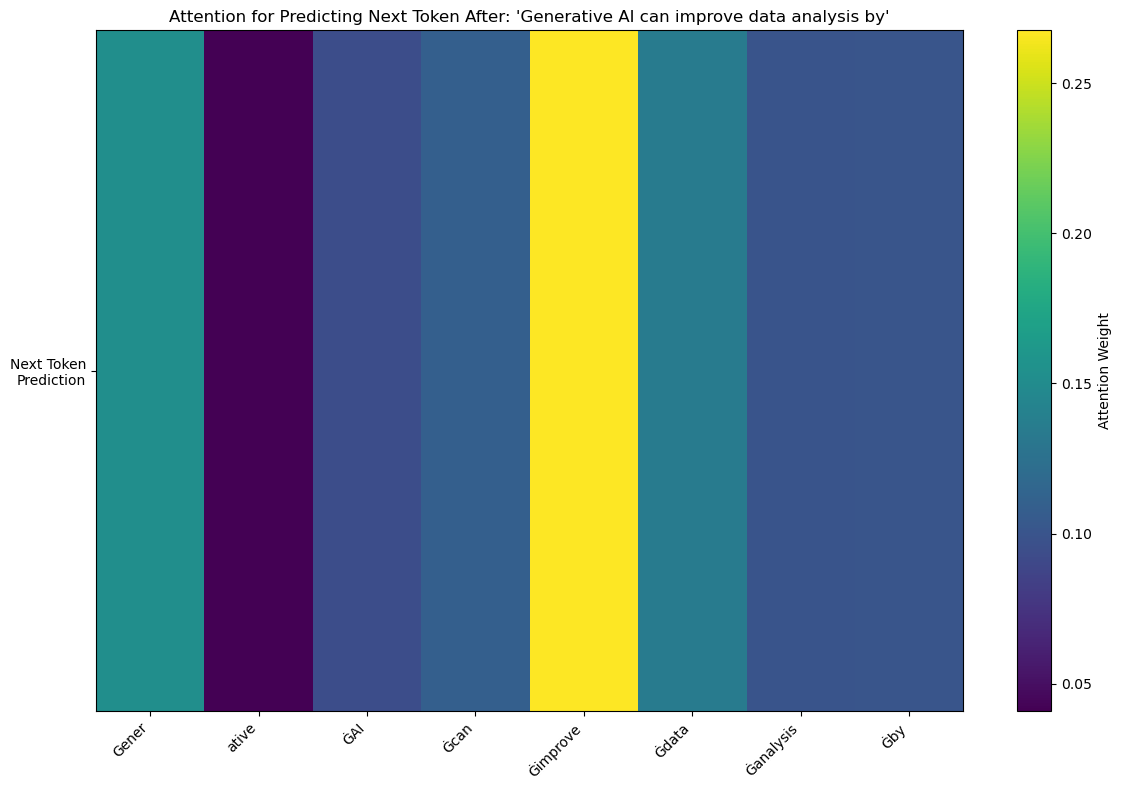

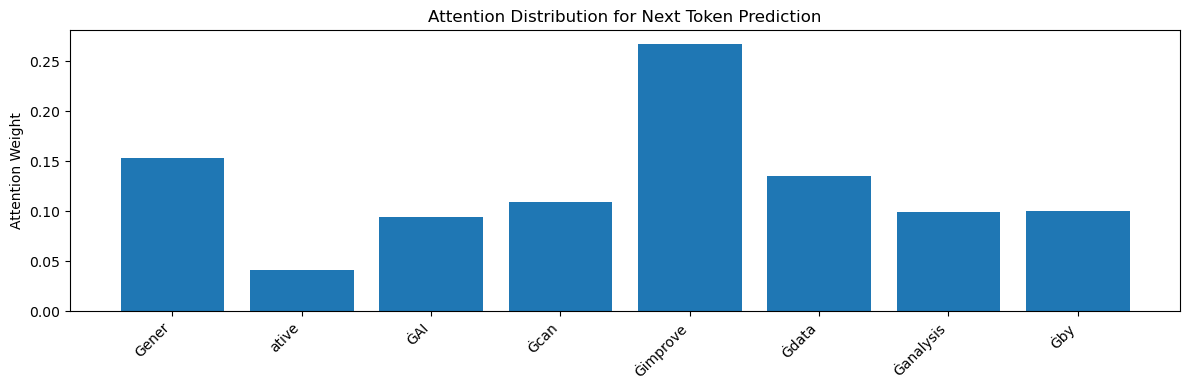

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from transformers import GPT2Model

def visualize_attention(prompt, model_name="gpt2"):
    """Visualize attention patterns in a small transformer model during generation."""
    # Load model and tokenizer for attention visualization
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = GPT2Model.from_pretrained(model_name, attn_implementation="eager")
    model.eval()
    
    # Tokenize the prompt
    inputs = tokenizer(prompt, return_tensors="pt")
    
    # Get attention weights
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)
    
    # Extract attention weights (shape: [layers, batch, heads, seq_len, seq_len])
    attention = outputs.attentions
    
    # Get the input token strings for axis labels
    input_tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    
    # Create attention visualization
    plt.figure(figsize=(12, 8))
    
    # Take the last token's attention pattern from the last layer's last head
    # This shows what the model is attending to when predicting the next token
    last_layer_idx = len(attention) - 1
    last_token_idx = len(input_tokens) - 1
    head_idx = 0  # We could average across heads, but let's just take one attention head for simplicity
    
    # Get attention weights for the last token
    attn_weights = attention[last_layer_idx][0, head_idx, last_token_idx].numpy()
    
    # Create heatmap of attention weights
    plt.imshow(attn_weights.reshape(1, -1), cmap="viridis", aspect="auto")
    plt.colorbar(label="Attention Weight")
    
    # Set labels
    plt.yticks([0], ["Next Token\nPrediction"])
    plt.xticks(range(len(input_tokens)), input_tokens, rotation=45, ha="right")
    plt.title(f"Attention for Predicting Next Token After: '{prompt}'")
    plt.tight_layout()
    
    # Also visualize the distribution of attention across tokens
    plt.figure(figsize=(12, 4))
    plt.bar(range(len(input_tokens)), attn_weights)
    plt.xticks(range(len(input_tokens)), input_tokens, rotation=45, ha="right")
    plt.ylabel("Attention Weight")
    plt.title("Attention Distribution for Next Token Prediction")
    plt.tight_layout()
    
    # Return processed attention data for further analysis
    return {
        "tokens": input_tokens,
        "attention_weights": attn_weights,
        "prompt": prompt
    }

# Example visualization
business_prompt = "Generative AI can improve data analysis by"
attention_data = visualize_attention(business_prompt)

# Analyze which tokens receive the most attention
token_attention = list(zip(attention_data["tokens"], attention_data["attention_weights"]))
sorted_attention = sorted(token_attention, key=lambda x: x[1], reverse=True)

print(f"Prompt: '{business_prompt}'")
print("\nTokens ranked by attention weight (for predicting the next token):")
for token, weight in sorted_attention:
    print(f"  '{token}': {weight:.4f}")

## RAG with Vector Database
For implementing Retrieval-Augmented Generation in production systems:

In [9]:
from sentence_transformers import SentenceTransformer
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

class EnhancedRAGSystem:
   """Production-ready RAG implementation with proper document handling and metadata."""
  
   def __init__(self, documents, model_name='sentence-transformers/all-mpnet-base-v2'):
       """
       Initialize RAG system with documents.
      
       Args:
           documents: List of dictionaries with keys 'content' and 'metadata'
           model_name: Name of the sentence transformer model for embeddings
       """
       self.documents = documents
       self.embedding_model = SentenceTransformer(model_name)
      
       # Separate content from metadata for embedding
       self.document_contents = [doc['content'] for doc in documents]
       self.document_embeddings = self.embed_documents()
      
   def embed_documents(self):
       """Compute embeddings for all documents."""
       print(f"Embedding {len(self.document_contents)} documents...")
       return self.embedding_model.encode(self.document_contents, show_progress_bar=True)
  
   def retrieve(self, query, top_k=3, threshold=0.3):
       """
       Retrieve most relevant documents for a query with similarity threshold.
      
       Args:
           query: The search query
           top_k: Maximum number of documents to retrieve
           threshold: Minimum similarity score to include a document
          
       Returns:
           List of tuples (document, metadata, similarity_score)
       """
       # Embed query
       query_embedding = self.embedding_model.encode(query)
      
       # Calculate similarity scores
       similarities = cosine_similarity([query_embedding], self.document_embeddings)[0]
      
       # Get document indices above threshold
       indices = np.where(similarities >= threshold)[0]
      
       # Sort by similarity (highest first)
       sorted_indices = indices[np.argsort(similarities[indices])[::-1]]
      
       # Limit to top_k
       top_indices = sorted_indices[:top_k]
      
       # Return documents, metadata and scores
       results = []
       for i in top_indices:
           results.append((
               self.document_contents[i],
               self.documents[i].get('metadata', {}),
               similarities[i]
           ))
      
       return results
  
   def generate_with_retrieval(self, query, llm_generator, format_prompt=None):
       """
       Generate response using retrieved context and an LLM.
      
       Args:
           query: User query
           llm_generator: Function that takes a prompt and returns generated text
           format_prompt: Optional custom prompt formatter
          
       Returns:
           Generated response and retrieval metadata
       """
       # Get relevant documents
       retrieved_docs = self.retrieve(query)
      
       # Default prompt formatter if none provided
       if format_prompt is None:
           def format_prompt(query, docs):
               context = "\n\n".join([doc[0] for doc in docs])
               return f"Context information:\n{context}\n\nQuestion: {query}\n\nAnswer:"
      
       # Create prompt with context
       prompt = format_prompt(query, retrieved_docs)
      
       # Generate response
       response = llm_generator(prompt)
      
       # Return response and retrieval metadata
       return {
           "response": response,
           "retrieved_documents": [
               {
                   "content_preview": doc[0][:100] + "..." if len(doc[0]) > 100 else doc[0],
                   "metadata": doc[1],
                   "similarity_score": doc[2]
               }
               for doc in retrieved_docs
           ],
           "query": query
       }


# Example document collection for a business analytics scenario
analytics_documents = [
   {
       "content": "Generative AI can create synthetic datasets that preserve statistical properties of original data while protecting privacy. This technique helps data scientists test models with realistic but non-sensitive information.",
       "metadata": {"source": "internal_whitepaper", "author": "Data Science Team", "date": "2023-05-15"}
   },
   {
       "content": "When implementing generative AI in business workflows, it's essential to maintain human oversight for critical decisions. The technology should augment rather than replace human judgment.",
       "metadata": {"source": "best_practices", "author": "Ethics Committee", "date": "2023-06-22"}
   },
   {
       "content": "Text-to-SQL applications of generative AI allow business analysts without SQL expertise to query databases using natural language. This democratizes data access across organizations.",
       "metadata": {"source": "use_case_study", "author": "Analytics Department", "date": "2023-04-10"}
   },
   {
       "content": "Attention visualization in transformer models helps data scientists understand why models make specific predictions, improving explainability and trust.",
       "metadata": {"source": "technical_guide", "author": "ML Engineering", "date": "2023-07-05"}
   },
   {
       "content": "Hallucinations in generative AI occur when models produce plausible but incorrect information. Implementing fact-checking mechanisms is essential for business critical applications.",
       "metadata": {"source": "risk_assessment", "author": "Quality Assurance", "date": "2023-08-18"}
   }
]


# Simple LLM generator mock function (in production, this would call an actual LLM API)
def mock_llm_generator(prompt):
   """Simulate an LLM response for demonstration purposes."""
   # In a real implementation, this would call an API like:
   # response = openai.ChatCompletion.create(model="gpt-3.5-turbo", messages=[{"role": "user", "content": prompt}])
   return f"Based on the provided context, here's the answer to your question..."


# Initialize RAG system
rag_system = EnhancedRAGSystem(analytics_documents)


# Example query
query = "How can we prevent hallucinations in generative AI for business applications?"
result = rag_system.generate_with_retrieval(query, mock_llm_generator)


# Display results
print(f"Query: {result['query']}\n")
print(f"Response: {result['response']}\n")
print("Retrieved Documents:")
for i, doc in enumerate(result['retrieved_documents']):
   print(f"{i+1}. {doc['content_preview']} (Score: {doc['similarity_score']:.4f})")
   print(f"   Source: {doc['metadata']['source']} | Author: {doc['metadata']['author']}")

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Embedding 5 documents...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Query: How can we prevent hallucinations in generative AI for business applications?

Response: Based on the provided context, here's the answer to your question...

Retrieved Documents:
1. Hallucinations in generative AI occur when models produce plausible but incorrect information. Imple... (Score: 0.7543)
   Source: risk_assessment | Author: Quality Assurance
2. When implementing generative AI in business workflows, it's essential to maintain human oversight fo... (Score: 0.5783)
   Source: best_practices | Author: Ethics Committee
3. Generative AI can create synthetic datasets that preserve statistical properties of original data wh... (Score: 0.4209)
   Source: internal_whitepaper | Author: Data Science Team


## Summary
After exploring the inner workings of generative AI, we've now seen how these models decide what to say next through token probability distributions. We've examined how different sampling methods, from greedy to temperature sampling and nucleus sampling, dramatically affect the creativity and coherence of generated text. By visualizing attention scores, we've observed how models weigh the importance of previous tokens when generating new ones, revealing the mechanism behind contextual understanding. Finally, our conceptual implementation of Retrieval-Augmented Generation (RAG) demonstrated how external knowledge can be integrated into the generation process, enhancing factuality and reducing hallucinations. These fundamental concepts form the building blocks of today's most advanced AI text systems and provide a framework for understanding future innovations in generative AI.